# Chicago Crime 2022: Classification without Leakage

Three questions a police analyst might ask about a new incident report: **what kind of crime** is likely at this place and time, will it
**end in an arrest**, and is it **domestic**? Each sounds like a standard classification task, but police records are full of columns that
give the answer away. This notebook audits that leakage first, then builds honest models with a strict time split and explains them.

**Objectives**
1. Which columns leak the answer, and why?
2. How well can the crime type be predicted from place and time alone?
3. Which incidents end in an arrest — and how different is the answer once police-initiated crimes are removed?
4. Which incidents are domestic, using only information available when the report is made?
5. What drives each model, and where does it fail?

**Data** → [Kaggle dataset "Crime Prediction in Chicago 2022"](https://www.kaggle.com/search?q=crime+prediction+in+chicago+2022) · 239,558 incidents · 1 Jan – 31 Dec 2022

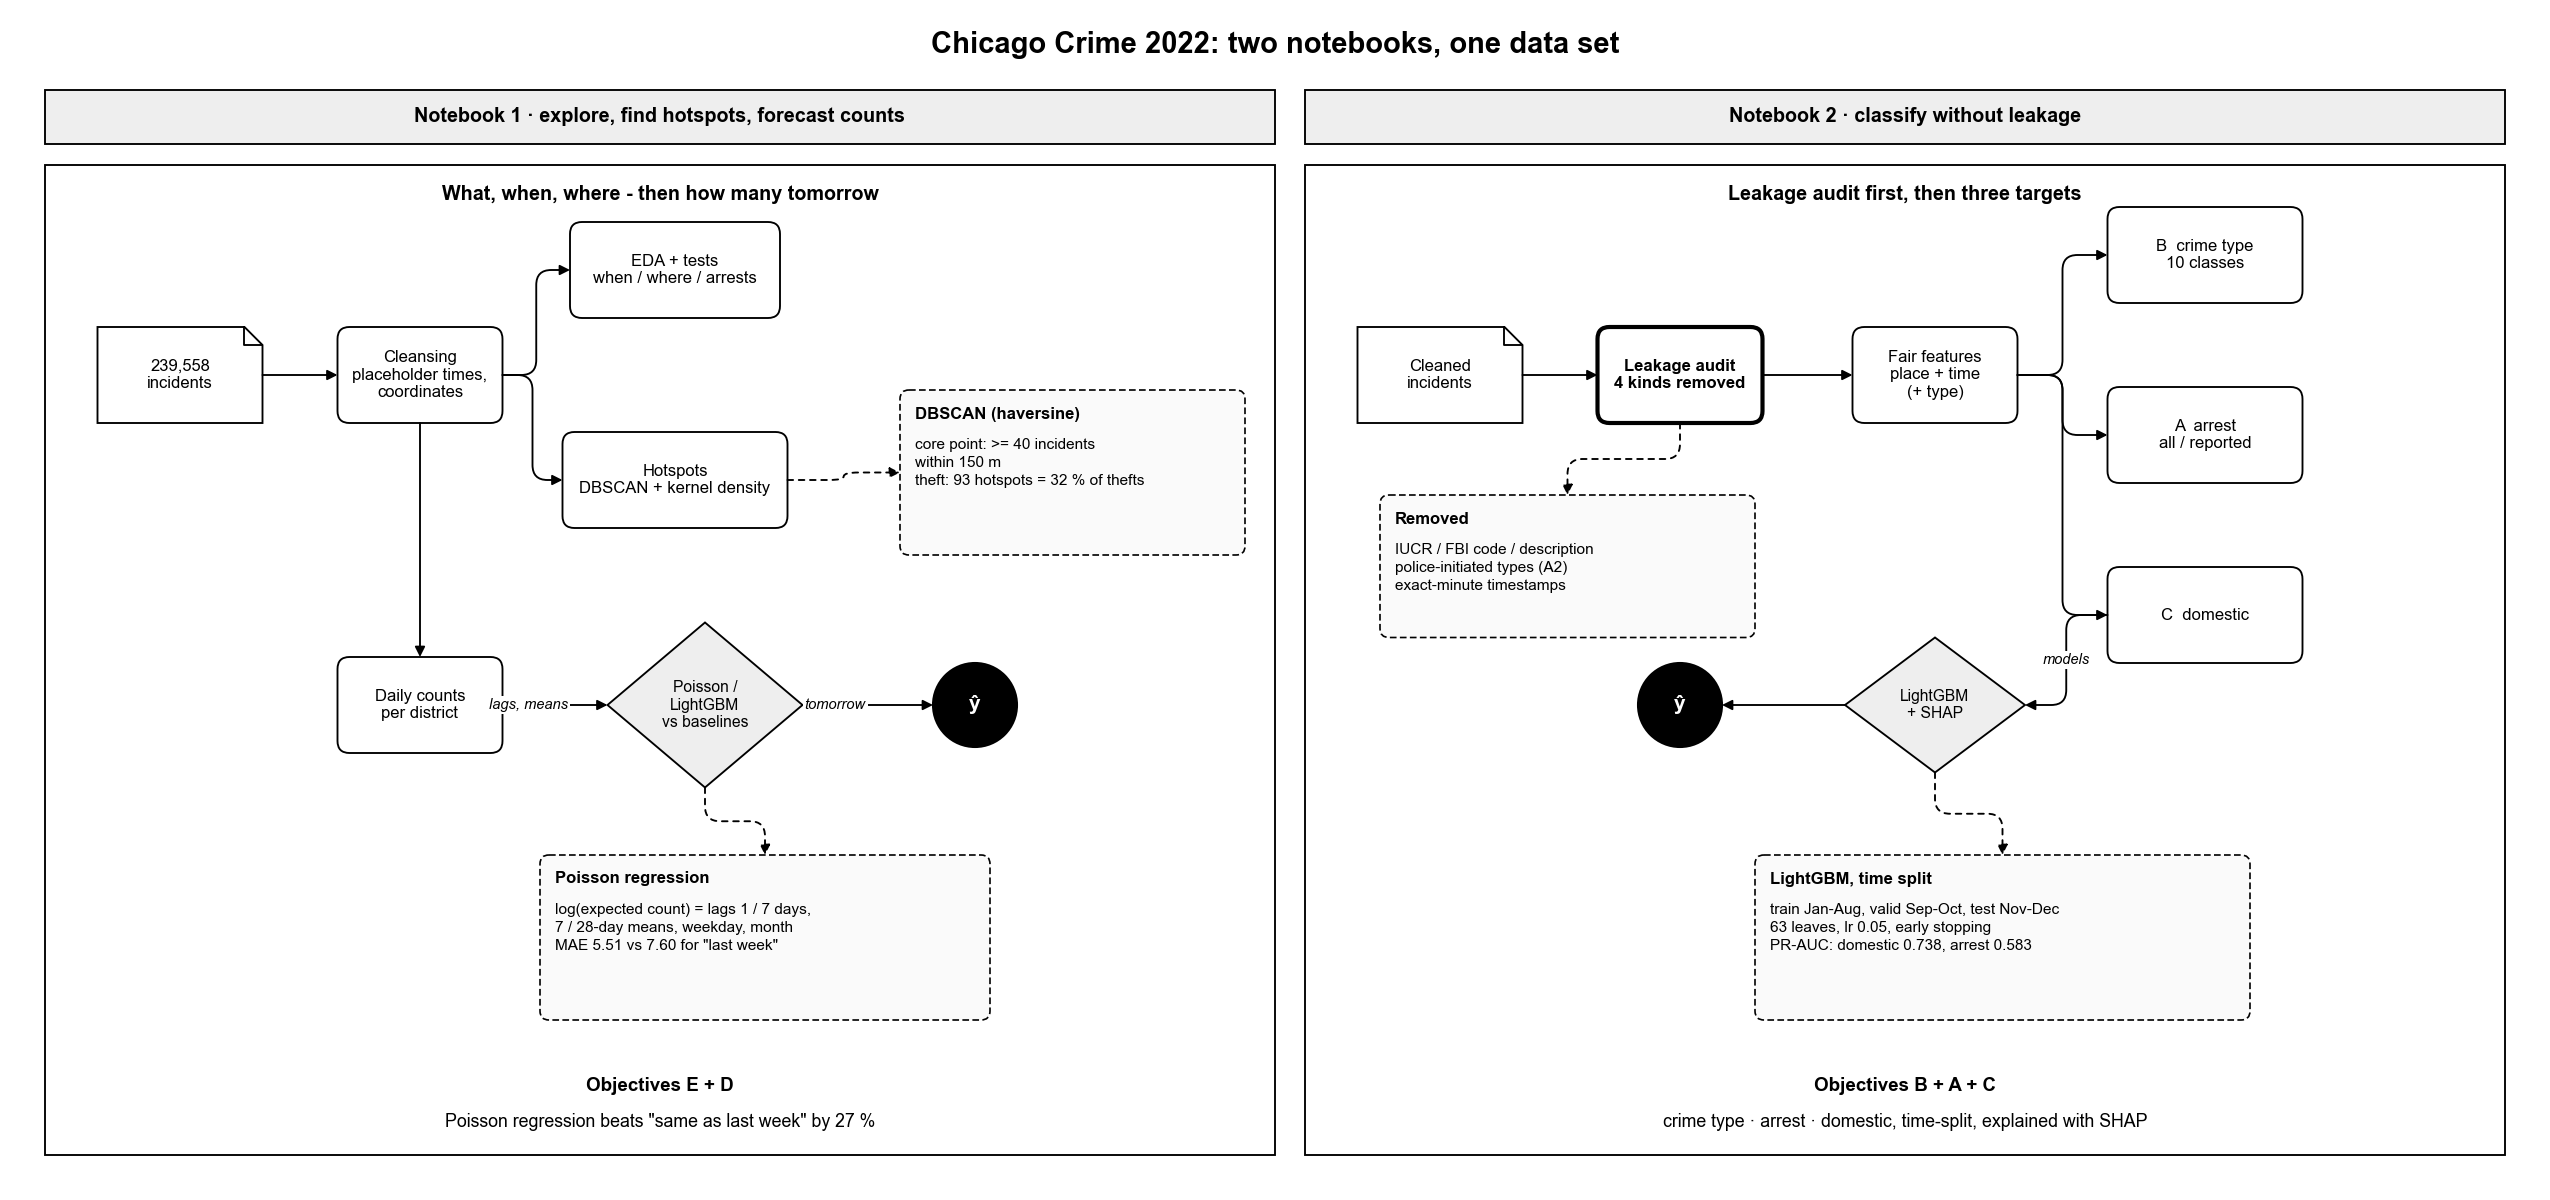

<!-- objective -->
## Objective

- **Problem** → a city has limited patrols, detectives and victim-support staff; it needs to know *what* happens *when* and *where*, how busy tomorrow will be, and which new reports need attention first
- **Why this repo** → clean the hidden recording artefacts, map the patterns, forecast daily counts per district, and classify new reports using only what is known when the report is filed
- **Real-world use** → patrol planning around theft hotspots, staffing from the daily forecast, and early flags for likely domestic cases so victim support can call sooner (never replacing the officer)

# [1/12] Setup

Set every knob once in the top cell → later cells only read them, and nothing is written unless `SAVE_FIGURES = True`

In [ ]:
"""Optional · Edit the settings, then run all cells. Explanations: README.md

[1/7] DATA_DIR: dataset folder (searched recursively under /kaggle/input for the crime CSV if not found here)
    Default = '/kaggle/input'
[2/7] WORK_DIR: folder for exported figures
    Default = '/kaggle/working'
[3/7] SEED: random seed
    Default = 42
[4/7] VALID_START / TEST_START: time split (train before VALID_START, validate until TEST_START, test after)
    Default = '2022-09-01' / '2022-11-01'
[5/7] N_TYPE_CLASSES: crime types kept as their own class (the rest become OTHER)
    Default = 9
[6/7] N_LOCATIONS: location descriptions kept (the rest become OTHER)
    Default = 40
[7/7] SAVE_FIGURES: write every chart to WORK_DIR/assets
    Default = False
"""
DATA_DIR       = '/kaggle/input'
WORK_DIR       = '/kaggle/working'
SEED           = 42
VALID_START    = '2022-09-01'
TEST_START     = '2022-11-01'
N_TYPE_CLASSES = 9
N_LOCATIONS    = 40
SAVE_FIGURES   = False

CHICAGO_BOX    = {'lat': (41.64, 42.03), 'lon': (-87.95, -87.52)}
POLICE_INITIATED = ['NARCOTICS', 'WEAPONS VIOLATION', 'CONCEALED CARRY LICENSE VIOLATION', 'PROSTITUTION', 'LIQUOR LAW VIOLATION',
                    'GAMBLING', 'INTERFERENCE WITH PUBLIC OFFICER', 'PUBLIC INDECENCY', 'PUBLIC PEACE VIOLATION', 'OBSCENITY']
SHAP_SAMPLE    = 3000
PAD            = 34
PALETTE        = {'main': 'black', 'flag': 'red', 'soft': 'grey'}

In [ ]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

import lightgbm as lgb
import shap
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix, f1_score, log_loss,
                             mutual_info_score, precision_recall_curve, roc_auc_score, top_k_accuracy_score)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings('ignore')
sns.set_style('darkgrid')
sns.set_palette('gray')
ASSETS = Path(WORK_DIR) / 'assets'
if SAVE_FIGURES:
    ASSETS.mkdir(parents=True, exist_ok=True)

In [ ]:
def show_block(title, items):
    print(f'{title}:')
    for key, value in items.items():
        print(f'    {key:<{PAD}}{value}')


def save(fig, name):
    if SAVE_FIGURES:
        fig.savefig(ASSETS / f'{name}.png', bbox_inches='tight', dpi=110)


def find_crime_csv(root):
    import csv
    root = Path(root)
    candidates = [root] if root.is_file() else sorted(root.rglob('*.csv')) if root.exists() else []
    for f in candidates:
        with open(f, newline='', encoding='utf-8', errors='ignore') as fh:
            header = next(csv.reader(fh), [])
        if {'Primary Type', 'Arrest', 'Domestic', 'Beat'} <= set(header):
            return f
    raise FileNotFoundError(f'(!) No Chicago crime CSV under {root}.\n'
                            f'    Add Input -> Datasets -> search "Crime Prediction in Chicago 2022"')


def binary_scores(y, p, threshold, name):
    pred = p >= threshold
    return {'model': name, 'PR-AUC': average_precision_score(y, p), 'ROC-AUC': roc_auc_score(y, p),
            'F1': f1_score(y, pred), 'precision': (pred & (y == 1)).sum() / max(pred.sum(), 1),
            'recall': (pred & (y == 1)).sum() / max((y == 1).sum(), 1), 'threshold': threshold}


def best_f1_threshold(y, p):
    pr, rc, th = precision_recall_curve(y, p)
    f1 = 2 * pr * rc / np.clip(pr + rc, 1e-12, None)
    return float(th[np.nanargmax(f1[:-1])])

# [2/12] Data and cleansing

Load the incidents and apply the cleansing rules from the exploration notebook → placeholder times flagged, impossible coordinates removed, homicide victims kept

In [ ]:
raw = pd.read_csv(find_crime_csv(DATA_DIR))
df = raw.copy()
df['datetime'] = pd.to_datetime(df['Date'], format='%m/%d/%Y %H:%M')
df['hour'] = df['datetime'].dt.hour
df['minute'] = df['datetime'].dt.minute
df['weekday'] = df['datetime'].dt.dayofweek
df['month'] = df['datetime'].dt.month
df['time_placeholder'] = ((df['hour'] == 0) & df['minute'].isin([0, 1])) | ((df['hour'] == 12) & (df['minute'] == 0))
df['time_rounded'] = (df['minute'] == 0).astype(int)
outside = ~(df['Latitude'].between(*CHICAGO_BOX['lat']) & df['Longitude'].between(*CHICAGO_BOX['lon']))
df.loc[outside, ['Latitude', 'Longitude']] = np.nan
df['Location Description'] = df['Location Description'].fillna('UNKNOWN')
top_locations = df['Location Description'].value_counts().index[:N_LOCATIONS]
df['location'] = df['Location Description'].where(df['Location Description'].isin(top_locations), 'OTHER')
top_types = df['Primary Type'].value_counts().index[:N_TYPE_CLASSES]
df['type_class'] = df['Primary Type'].where(df['Primary Type'].isin(top_types), 'OTHER')
df['split'] = np.where(df['datetime'] < VALID_START, 'train', np.where(df['datetime'] < TEST_START, 'valid', 'test'))

In [ ]:
show_block('Data', {'incidents': f'{len(df):,}', 'placeholder times flagged': f"{df['time_placeholder'].sum():,}",
                    'type classes': f"{df['type_class'].nunique()} ({N_TYPE_CLASSES} types + OTHER)",
                    'location classes': df['location'].nunique()})
display(df['split'].value_counts().rename('incidents').to_frame())

# [3/12] Leakage audit

Measure how much each column tells about each target, and ask *when* that column becomes known → columns that define or follow the answer are removed

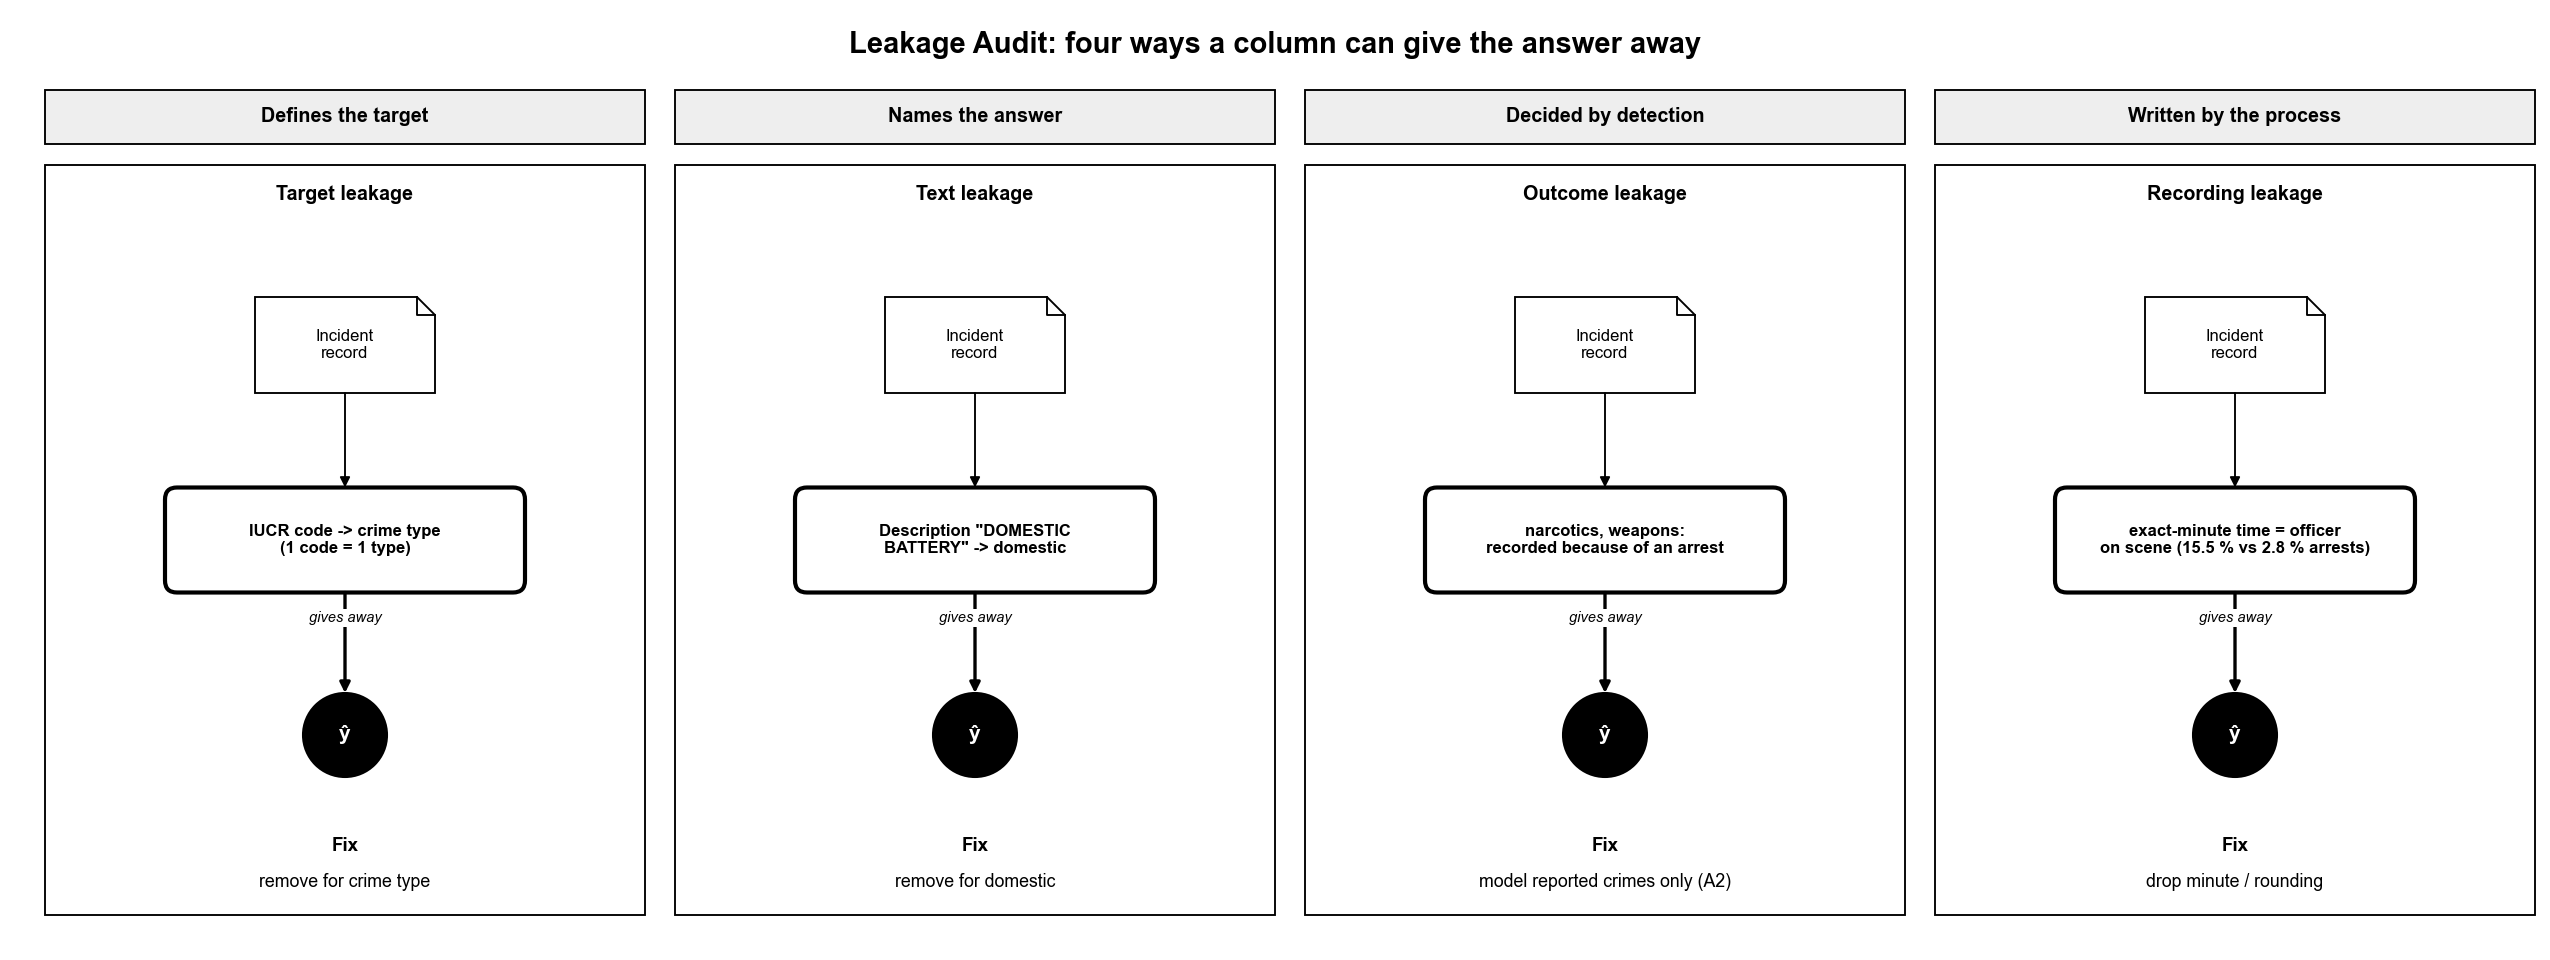

**Question:** Which columns leak the answer, and why?

$$I(X; Y) = \sum_{x, y} p(x, y)\,\log\frac{p(x, y)}{p(x)\,p(y)} \qquad \text{normalised: } \frac{I(X; Y)}{H(Y)} \in [0, 1]$$
- **Mutual information** → how many bits a column reveals about the target; divided by the target's entropy $H(Y)$, 1 means "the column alone gives the answer"
- **Timing test** → a fair feature must be known when the report is created, *before* the outcome
- **Process test** → a feature can also leak by describing *how the record was written* (e.g. how precisely the time was typed in)
- Analogy → predicting the winner of a match while the final score is in the dataset: perfect accuracy, zero use

**Answer:** four leaks, all removed.
- **defines the target** → `IUCR` reveals the type completely (1.00), `FBI Code` 0.95, `Description` 0.94
- **names the answer** → `Description` containing "DOMESTIC" is always domestic
- **decided by detection / by the process** → narcotics ≈ arrest; exact-minute times end in arrest 15.5 % vs 2.8 % (officer on scene) → `minute` dropped

In [ ]:
def entropy(y):
    p = pd.Series(y).value_counts(normalize=True).to_numpy()
    return float(-(p * np.log(p)).sum())


targets = {'crime type': df['type_class'], 'arrest': df['Arrest'], 'domestic': df['Domestic']}
candidates = {'IUCR': df['IUCR'], 'Description': df['Description'], 'FBI Code': df['FBI Code'], 'Primary Type': df['Primary Type'],
              'Arrest': df['Arrest'], 'Domestic': df['Domestic'], 'Location Description': df['location'],
              'Beat': df['Beat'], 'District': df['District'], 'hour': df['hour'], 'weekday': df['weekday'], 'month': df['month']}
leak = pd.DataFrame({t: {c: mutual_info_score(y, x) / entropy(y) for c, x in candidates.items() if c != t.title()}
                     for t, y in targets.items()})
leak.loc['Primary Type', 'crime type'] = np.nan          # the target itself
leak.loc['Arrest', 'arrest'] = np.nan
leak.loc['Domestic', 'domestic'] = np.nan
iucr_types = df.groupby('IUCR')['Primary Type'].nunique().max()
desc_domestic = df.loc[df['Description'].str.contains('DOMESTIC', na=False), 'Domestic'].mean()
arrest_by_iucr = df.groupby('IUCR')['Arrest'].mean()

fig, ax = plt.subplots(figsize=(9, 6.5))
sns.heatmap(leak, annot=True, fmt='.2f', cmap='Reds', vmin=0, vmax=1, ax=ax, cbar_kws={'label': 'normalised mutual information'})
ax.set(title='How much each column reveals about each target')
save(fig, '09_leakage')
plt.show()

In [ ]:
precision = np.select([df['time_placeholder'], df['minute'] == 0, df['minute'] % 5 == 0],
                      ['placeholder (00:00, 00:01, 12:00)', 'full hour', 'multiple of 5 minutes'], 'exact minute')
reported_mask = ~df['Primary Type'].isin(POLICE_INITIATED)
precision_arrest = (df[reported_mask].groupby(precision[reported_mask])['Arrest'].agg(['mean', 'size'])
                    .rename(columns={'mean': 'arrest rate', 'size': 'reported incidents'}).sort_values('arrest rate', ascending=False))

show_block('Leakage evidence', {'types per IUCR code (max)': iucr_types,
                                'domestic share when Description says DOMESTIC': f'{desc_domestic:.1%}',
                                'IUCR codes with arrest rate > 90 %': int((arrest_by_iucr > 0.9).sum()),
                                'IUCR codes with arrest rate < 5 %': int((arrest_by_iucr < 0.05).sum())})
display(precision_arrest.round(3))

# [4/12] Feature sets

Build the context features known when a report is created, and decide per task which extra columns are fair → three honest feature sets

In [ ]:
CONTEXT_NUM = ['Latitude', 'Longitude', 'hour', 'weekday', 'month']        # minute / rounding left out on purpose (section 3)
CONTEXT_CAT = ['location', 'District', 'Community Area', 'Beat']
FEATURE_SETS = pd.DataFrame([
    {'task': 'all tasks', 'features': 'hour, weekday, month, coordinates, beat, district, community area, location type', 'excluded': 'minute and time rounding (they record how the report was written, see section 3)'},
    {'task': 'B  crime type', 'features': 'place + time + location type', 'excluded': 'IUCR, Description, FBI Code (define the type); Arrest (happens later); Domestic'},
    {'task': 'A1 arrest, all crimes', 'features': 'context + crime type + domestic', 'excluded': 'IUCR, Description, FBI Code (finer versions of the type)'},
    {'task': 'A2 arrest, reported crimes', 'features': 'context + crime type + domestic', 'excluded': 'police-initiated types removed from the data'},
    {'task': 'C  domestic', 'features': 'context + crime type', 'excluded': 'Description and IUCR ("DOMESTIC BATTERY" etc. name the answer); Arrest'},
]).set_index('task')


def make_X(data, extra_cat=(), extra_num=()):
    X = data[CONTEXT_NUM + list(extra_num) + CONTEXT_CAT + list(extra_cat)].copy()
    for c in CONTEXT_CAT + list(extra_cat):
        X[c] = X[c].astype(str).astype('category')
    return X


def linear_model(extra_cat=(), extra_num=(), multiclass=False):
    pre = ColumnTransformer([
        ('num', make_pipeline(SimpleImputer(strategy='median'), StandardScaler()), CONTEXT_NUM + list(extra_num)),
        ('cat', OneHotEncoder(handle_unknown='ignore', min_frequency=20), CONTEXT_CAT + list(extra_cat))])
    return make_pipeline(pre, LogisticRegression(max_iter=300, C=1.0))


LGB_BASE = dict(n_estimators=3000, learning_rate=0.05, num_leaves=63, min_child_samples=50, subsample=0.8, subsample_freq=1,
                colsample_bytree=0.8, random_state=SEED, verbose=-1)

In [ ]:
display(FEATURE_SETS)

# [5/12] Objective B: crime type from place and time

Predict the type class (9 most common types + OTHER) from where and when an incident happens → compare with guessing the most common type

**Question:** How well can the crime type be predicted from place and time alone?

- **Accuracy** → share predicted exactly right; the baseline always predicts THEFT (the most common class)
- **Top-3 accuracy** → the true type is among the model's 3 most likely types — the useful view for planning ("expect theft, battery or damage here")
- **Macro-F1** → average F1 over classes, so rare types count as much as theft
- **Log-loss** → quality of the probabilities; the prior (class frequencies) is the reference

**Answer:** modestly, but better than guessing.
- accuracy 34.6 % vs 22.4 % (always theft); top-3 66.4 % vs 49.0 %; macro-F1 0.236 vs 0.037
- with the time-precision leak it looked better (68.9 % top-3)

In [ ]:
tr, va, te = (df[df['split'] == s] for s in ['train', 'valid', 'test'])
classes = sorted(df['type_class'].unique())
yb = {s: pd.Categorical(d['type_class'], categories=classes).codes for s, d in [('train', tr), ('valid', va), ('test', te)]}
Xb = {s: make_X(d) for s, d in [('train', tr), ('valid', va), ('test', te)]}

prior = np.bincount(yb['train'], minlength=len(classes)) / len(yb['train'])
lin_b = linear_model().fit(tr, yb['train'])
lgb_b = lgb.LGBMClassifier(objective='multiclass', **LGB_BASE).fit(
    Xb['train'], yb['train'], eval_set=[(Xb['valid'], yb['valid'])], callbacks=[lgb.early_stopping(100, verbose=False)])
probs_b = {'Prior (always THEFT)': np.tile(prior, (len(te), 1)), 'Logistic regression': lin_b.predict_proba(te),
           'LightGBM': lgb_b.predict_proba(Xb['test'])}
rows = []
for name, p in probs_b.items():
    rows.append({'model': name, 'accuracy': accuracy_score(yb['test'], p.argmax(1)),
                 'top-3 accuracy': top_k_accuracy_score(yb['test'], p, k=3, labels=range(len(classes))),
                 'macro-F1': f1_score(yb['test'], p.argmax(1), average='macro'), 'log-loss': log_loss(yb['test'], p, labels=range(len(classes)))})
board_b = pd.DataFrame(rows).set_index('model')

In [ ]:
show_block('Objective B', {'classes': len(classes), 'LightGBM trees': lgb_b.best_iteration_,
                           'test incidents': f'{len(te):,}'})
display(board_b.round(3))

# [6/12] Objective B: where the type model succeeds and fails

Read the confusion matrix and the per-class recall → location type separates some crimes clearly, most remain mixed

In [ ]:
pred_b = probs_b['LightGBM'].argmax(1)
cm = confusion_matrix(yb['test'], pred_b, normalize='true')
recall_b = pd.Series(np.diag(cm), index=classes).sort_values(ascending=False)
imp_b = pd.Series(lgb_b.booster_.feature_importance('gain'), index=Xb['train'].columns).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(20, 7.5), gridspec_kw={'width_ratios': [1.4, 1]})
sns.heatmap(cm, annot=True, fmt='.2f', cmap='Greys', xticklabels=[c.title()[:14] for c in classes],
            yticklabels=[c.title()[:14] for c in classes], ax=axes[0], cbar=False)
axes[0].set(title='Crime type: confusion matrix (rows = true, row-normalised)', xlabel='predicted', ylabel='true')
axes[1].barh(imp_b.index, imp_b.values / imp_b.sum(), color=PALETTE['main'])
axes[1].set(title='LightGBM feature importance (share of gain)')
fig.tight_layout()
save(fig, '10_type_model')
plt.show()

In [ ]:
display(recall_b.rename('recall').round(3).to_frame().T)

**Question:** Which crimes can place and time identify?

**Answer:** only crimes with their own kind of place: theft 62 %, battery 59 %, car theft 41 %, fraud 39 % recall.
Assault, robbery and damage (≤ 7 %) happen anywhere and look like theft or battery.

# [7/12] Objective A: arrest prediction, two versions

Predict whether an incident ends in an arrest, first for all crimes, then only for crimes reported by the public → the honest version is much harder

**Question:** Which incidents end in an arrest — and what changes when police-initiated crimes are removed?

- **A1, all crimes** → context + crime type + domestic flag. Police-initiated types (narcotics, weapons …) are almost always recorded *with*
  an arrest, so the model mostly learns the type
- **A2, reported crimes** → the same features, but those types are removed: *which crimes reported by the public get solved by an arrest?*
- **PR-AUC** → threshold-free quality for a rare positive class (random = the arrest rate); the threshold for F1 is chosen on validation data

**Answer:** mostly through the crime type.
- A1 all crimes: PR-AUC 0.583 vs 0.101 base (recall 44 %, precision 67 %)
- A2 reported crimes: PR-AUC 0.276 vs 0.069 — much harder once "narcotics → arrest" is gone
- LightGBM beats logistic regression in both (interactions)

In [ ]:
def run_binary(data, target, extra_cat, extra_num=(), label=''):
    tr_, va_, te_ = (data[data['split'] == s] for s in ['train', 'valid', 'test'])
    X = {s: make_X(d, extra_cat, extra_num) for s, d in [('train', tr_), ('valid', va_), ('test', te_)]}
    y = {s: d[target].astype(int).to_numpy() for s, d in [('train', tr_), ('valid', va_), ('test', te_)]}
    lin = linear_model(extra_cat, extra_num).fit(tr_, y['train'])
    gbm = lgb.LGBMClassifier(**LGB_BASE).fit(X['train'], y['train'], eval_set=[(X['valid'], y['valid'])],
                                             callbacks=[lgb.early_stopping(100, verbose=False)])
    out = []
    base_rate = y['train'].mean()
    out.append({'model': f'{label}: base rate', 'PR-AUC': y['test'].mean(), 'ROC-AUC': 0.5, 'F1': np.nan,
                'precision': np.nan, 'recall': np.nan, 'threshold': np.nan})
    for name, m, Xv, Xt in [('logistic regression', lin, va_, te_), ('LightGBM', gbm, X['valid'], X['test'])]:
        thr = best_f1_threshold(y['valid'], m.predict_proba(Xv)[:, 1])
        out.append(binary_scores(y['test'], m.predict_proba(Xt)[:, 1], thr, f'{label}: {name}'))
    return pd.DataFrame(out).set_index('model'), gbm, X, y


df['crime_type'] = df['Primary Type']
reported = df[~df['Primary Type'].isin(POLICE_INITIATED)]
board_a1, gbm_a1, X_a1, y_a1 = run_binary(df, 'Arrest', ['crime_type'], ['Domestic'], 'A1 all crimes')
board_a2, gbm_a2, X_a2, y_a2 = run_binary(reported, 'Arrest', ['crime_type'], ['Domestic'], 'A2 reported crimes')
board_a = pd.concat([board_a1, board_a2])

In [ ]:
show_block('Objective A', {'A1 incidents / arrest rate': f"{len(df):,} / {df['Arrest'].mean():.1%}",
                           'A2 incidents / arrest rate': f"{len(reported):,} / {reported['Arrest'].mean():.1%}",
                           'police-initiated incidents removed': f"{len(df) - len(reported):,}"})
display(board_a.round(3))

# [8/12] Objective A: what drives an arrest for reported crimes?

Explain the A2 LightGBM with SHAP → which crime types, places and times make an arrest more or less likely

In [ ]:
Xs = X_a2['test'].sample(SHAP_SAMPLE, random_state=SEED)
sv_a2 = shap.TreeExplainer(gbm_a2)(Xs)
vals = sv_a2.values if sv_a2.values.ndim == 2 else sv_a2.values[:, :, 1]
imp_a2 = pd.Series(np.abs(vals).mean(0), index=Xs.columns).sort_values(ascending=False)
type_rate = reported[reported['split'] != 'test'].groupby('crime_type')['Arrest'].agg(['mean', 'size'])
type_rate = type_rate[type_rate['size'] >= 300].sort_values('mean', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(18, 6))
axes[0].barh(imp_a2.index[::-1], imp_a2.values[::-1], color=PALETTE['main'])
axes[0].set(title='A2 (reported crimes): mean |SHAP| per feature')
axes[1].barh(type_rate.index[::-1], type_rate['mean'][::-1] * 100, color=PALETTE['flag'])
axes[1].set(title='Arrest rate of reported crime types (%), train + valid')
fig.tight_layout()
save(fig, '11_arrest_drivers')
plt.show()

In [ ]:
display(imp_a2.round(4).to_frame('mean |SHAP|').T)

**Question:** Beyond the crime type, what makes an arrest more likely?

**Answer:** type first, then place.
- homicide 41.8 % and trespass 29.4 % vs fraud 1.7 %, car theft 2.9 %
- grocery / department stores 22.4 % / 19.5 % (store security) vs 7.5 % average
- (!) describes how crimes are discovered, not where arrests "should" happen

# [9/12] Objective C: domestic incidents

Predict whether an incident is domestic from context and crime type, without the description → the crime type and the location carry most of the signal

**Question:** Which incidents are domestic, using only information available when the report is made?

**Answer:** well — PR-AUC 0.738 vs 0.167 base, recall 76 % at precision 63 %.
Predicted and actual rates match by type (battery 55.1 % vs 55.9 %).

In [ ]:
board_c, gbm_c, X_c, y_c = run_binary(df, 'Domestic', ['crime_type'], (), 'C domestic')
p_c = gbm_c.predict_proba(X_c['test'])[:, 1]
by_type_c = pd.DataFrame({'type': X_c['test']['crime_type'].astype(str), 'y': y_c['test'], 'p': p_c})
by_type_c = by_type_c.groupby('type').agg(incidents=('y', 'size'), domestic_rate=('y', 'mean'),
                                          mean_predicted=('p', 'mean')).query('incidents >= 300').sort_values('domestic_rate', ascending=False)

In [ ]:
display(board_c.round(3))
display(by_type_c.round(3).head(10))

# [10/12] Objective C: what makes an incident domestic?

Explain the domestic model with SHAP → location type and crime type dominate, time adds a little

In [ ]:
Xs_c = X_c['test'].sample(SHAP_SAMPLE, random_state=SEED)
sv_c = shap.TreeExplainer(gbm_c)(Xs_c)
vals_c = sv_c.values if sv_c.values.ndim == 2 else sv_c.values[:, :, 1]
imp_c = pd.Series(np.abs(vals_c).mean(0), index=Xs_c.columns).sort_values(ascending=False)
loc_rate = df[df['split'] != 'test'].groupby('location')['Domestic'].agg(['mean', 'size']).query('size >= 1000').sort_values('mean', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(18, 6))
axes[0].barh(imp_c.index[::-1], imp_c.values[::-1], color=PALETTE['main'])
axes[0].set(title='Domestic model: mean |SHAP| per feature')
axes[1].barh(loc_rate.index[:12][::-1], loc_rate['mean'][:12][::-1] * 100, color=PALETTE['flag'])
axes[1].set(title='Domestic share by location (%), train + valid')
fig.tight_layout()
save(fig, '12_domestic_drivers')
plt.show()

In [ ]:
display(imp_c.round(4).to_frame('mean |SHAP|').T)

**Question:** What makes an incident domestic, and how would the model be used?

**Answer:** crime type and location: apartments 46 % and residences 40 % domestic vs ~1 % in stores; battery 56 %.
Use → flag likely domestic cases early for victim support, never replacing the officer's judgement.

# [11/12] Leaderboard

Put all objectives side by side → what a fair model can and cannot know from a fresh report

In [ ]:
summary_rows = [
    {'objective': 'B  crime type (10 classes)', 'metric': 'top-3 accuracy', 'baseline': board_b.loc['Prior (always THEFT)', 'top-3 accuracy'],
     'best model': board_b['top-3 accuracy'].drop('Prior (always THEFT)').max()},
    {'objective': 'B  crime type (10 classes)', 'metric': 'accuracy', 'baseline': board_b.loc['Prior (always THEFT)', 'accuracy'],
     'best model': board_b['accuracy'].drop('Prior (always THEFT)').max()},
    {'objective': 'A1 arrest, all crimes', 'metric': 'PR-AUC', 'baseline': board_a1['PR-AUC'].iloc[0], 'best model': board_a1['PR-AUC'].iloc[1:].max()},
    {'objective': 'A2 arrest, reported crimes', 'metric': 'PR-AUC', 'baseline': board_a2['PR-AUC'].iloc[0], 'best model': board_a2['PR-AUC'].iloc[1:].max()},
    {'objective': 'C  domestic', 'metric': 'PR-AUC', 'baseline': board_c['PR-AUC'].iloc[0], 'best model': board_c['PR-AUC'].iloc[1:].max()},
]
leaderboard = pd.DataFrame(summary_rows).set_index('objective')
leaderboard['lift over baseline'] = leaderboard['best model'] / leaderboard['baseline']

In [ ]:
display(leaderboard.round(3))

# [12/12] Summary

**Answer:**
- **Leakage first** → codes, descriptions, detection and timestamp precision all leaked; removed
- **B type** → 34.6 % accuracy, 66.4 % top-3 from place and time
- **A arrest** → PR-AUC 0.583 (all) / 0.276 (reported); **C domestic** → 0.738
- **Lesson** → how a record is created can leak more than suspicious columns